some trained models:

1. model_1: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=10, BATCH_SIZE=4, train.nlayer=4

2. model_2: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=20, BATCH_SIZE=4, train.nlayer=4

3. model_3: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=30, BATCH_SIZE=4, train.nlayer=4

4. model_4: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=40, BATCH_SIZE=4, train.nlayer=4

5. model_5: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=50, BATCH_SIZE=4, train.nlayer=4

6. model_6: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=60, BATCH_SIZE=4, train.nlayer=4

7. model_7: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=70, BATCH_SIZE=4, train.nlayer=4

8. model_8: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=80, BATCH_SIZE=4, train.nlayer=4

9. model_9: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=90, BATCH_SIZE=4, train.nlayer=4

10. model_10: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=100, BATCH_SIZE=4, train.nlayer=4


https://neptune.ai/blog/f1-score-accuracy-roc-auc-pr-auc

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import torch

In [17]:
# paths of models
model_1_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_2_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E20.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_3_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E30.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_4_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E40.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_5_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_6_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E60.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_7_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E70.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_8_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E80.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_9_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E90.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"
model_10_dir = "../results/adbench/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E100.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/train_seed=0.transform=quantile.feat_truncation=subsampling"


# paths of models
model_1_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_2_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E20.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_3_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E30.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_4_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E40.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_5_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_6_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E60.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_7_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E70.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_8_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E80.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_9_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E90.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_10_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E100.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"

#Fomo-0D model
default_dir = "../results/adbench/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/train_seed=0.transform=quantile.feat_truncation=subsampling"

model_5_best_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E50.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/best.ckpt"
model_10_best_dir_loss = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E100.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/best.ckpt"

#Fomo-0D model
default_dir_best_loss = "../ckpt/context5000.feat100.R500.inf-fullFalse.LTFalse.gen1tr1True.reuse100.E200.step1000.bs8.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1/seed0/best.ckpt"

### 1. Model_1

In [3]:
with open(model_1_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_1 = data["train_loss"]
val_loss_1 = data["val_loss"]
model_1_train_time = data['train_time']

print("Train time in second", model_1_train_time)
model_1_aucroc_scores = []
model_1_aucpr_scores = []
model_1_f1_scores = []
model_1_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_1_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_1_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_1_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_1_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_1_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_1_avg_aucroc = sum(model_1_aucroc_scores) / len(model_1_aucroc_scores)
model_1_avg_aucpr = sum(model_1_aucpr_scores) / len(model_1_aucpr_scores)
model_1_avg_f1 = sum(model_1_f1_scores) / len(model_1_f1_scores)
model_1_time_per_instance_avg = sum(model_1_time_per_instance) / len(model_1_time_per_instance)

print(f"number of datasets: {len(model_1_aucroc_scores)}")
print(f"Average aucroc: {model_1_avg_aucroc}")
print(f"Average aucpr: {model_1_avg_aucpr}")
print(f"Average f1: {model_1_avg_f1}")
print(f"Inference time per instance: {model_1_time_per_instance_avg}")

Train time in second 2470.707485437393
number of datasets: 121
Average aucroc: 0.7333058889362173
Average aucpr: 0.4213088402128753
Average f1: 0.41829633910560815
Inference time per instance: 4.979171702239355e-06


### 2. Model_2

In [4]:
with open(model_2_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_2 = data["train_loss"]
val_loss_2 = data["val_loss"]
model_2_train_time = data['train_time']

print("Train time in second", model_2_train_time)
model_2_aucroc_scores = []
model_2_aucpr_scores = []
model_2_f1_scores = []
model_2_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_2_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_2_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_2_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_2_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_2_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_2_avg_aucroc = sum(model_2_aucroc_scores) / len(model_2_aucroc_scores)
model_2_avg_aucpr = sum(model_2_aucpr_scores) / len(model_2_aucpr_scores)
model_2_avg_f1 = sum(model_2_f1_scores) / len(model_2_f1_scores)
model_2_time_per_instance_avg = sum(model_2_time_per_instance) / len(model_2_time_per_instance)

print(f"number of datasets: {len(model_2_aucroc_scores)}")
print(f"Average aucroc: {model_2_avg_aucroc}")
print(f"Average aucpr: {model_2_avg_aucpr}")
print(f"Average f1: {model_2_avg_f1}")
print(f"Inference time per instance: {model_2_time_per_instance_avg}")

Train time in second 4964.264281272888
number of datasets: 121
Average aucroc: 0.7390339279358105
Average aucpr: 0.4290496053067343
Average f1: 0.4236439439623536
Inference time per instance: 5.0105296823407135e-06


### 4. Model_3

In [5]:
with open(model_3_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_3 = data["train_loss"]
val_loss_3 = data["val_loss"]
model_3_train_time = data['train_time']

print("Train time in second", model_3_train_time)
model_3_aucroc_scores = []
model_3_aucpr_scores = []
model_3_f1_scores = []
model_3_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_3_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_3_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_3_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_3_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_3_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_3_avg_aucroc = sum(model_3_aucroc_scores) / len(model_3_aucroc_scores)
model_3_avg_aucpr = sum(model_3_aucpr_scores) / len(model_3_aucpr_scores)
model_3_avg_f1 = sum(model_3_f1_scores) / len(model_3_f1_scores)
model_3_time_per_instance_avg = sum(model_3_time_per_instance) / len(model_3_time_per_instance)

print(f"number of datasets: {len(model_3_aucroc_scores)}")
print(f"Average aucroc: {model_3_avg_aucroc}")
print(f"Average aucpr: {model_3_avg_aucpr}")
print(f"Average f1: {model_3_avg_f1}")
print(f"Inference time per instance: {model_3_time_per_instance_avg}")

Train time in second 9731.507739782333
number of datasets: 121
Average aucroc: 0.7201614607957915
Average aucpr: 0.4090241869719313
Average f1: 0.406593320118213
Inference time per instance: 1.0350580729375283e-05


### 4. Model_4

In [6]:
with open(model_4_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_4 = data["train_loss"]
val_loss_4 = data["val_loss"]
model_4_train_time = data['train_time']

print("Train time in second", model_4_train_time)
model_4_aucroc_scores = []
model_4_aucpr_scores = []
model_4_f1_scores = []
model_4_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_4_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_4_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_4_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_4_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_4_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_4_avg_aucroc = sum(model_4_aucroc_scores) / len(model_4_aucroc_scores)
model_4_avg_aucpr = sum(model_4_aucpr_scores) / len(model_4_aucpr_scores)
model_4_avg_f1 = sum(model_4_f1_scores) / len(model_4_f1_scores)
model_4_time_per_instance_avg = sum(model_4_time_per_instance) / len(model_4_time_per_instance)

print(f"number of datasets: {len(model_4_aucroc_scores)}")
print(f"Average aucroc: {model_4_avg_aucroc}")
print(f"Average aucpr: {model_4_avg_aucpr}")
print(f"Average f1: {model_4_avg_f1}")
print(f"Inference time per instance: {model_4_time_per_instance_avg}")

Train time in second 10042.910488843918
number of datasets: 121
Average aucroc: 0.7268332469056661
Average aucpr: 0.4124379957261358
Average f1: 0.4134940695145728
Inference time per instance: 4.905366513583685e-06


### 5. model_5

In [7]:
with open(model_5_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_5 = data["train_loss"]
val_loss_5 = data["val_loss"]
model_5_train_time = data['train_time']

print("Train time in second", model_5_train_time)
model_5_aucroc_scores = []
model_5_aucpr_scores = []
model_5_f1_scores = []
model_5_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_5_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_5_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_5_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_5_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_5_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_5_avg_aucroc = sum(model_5_aucroc_scores) / len(model_5_aucroc_scores)
model_5_avg_aucpr = sum(model_5_aucpr_scores) / len(model_5_aucpr_scores)
model_5_avg_f1 = sum(model_5_f1_scores) / len(model_5_f1_scores)
model_5_time_per_instance_avg = sum(model_5_time_per_instance) / len(model_5_time_per_instance)

print(f"number of datasets: {len(model_5_aucroc_scores)}")
print(f"Average aucroc: {model_5_avg_aucroc}")
print(f"Average aucpr: {model_5_avg_aucpr}")
print(f"Average f1: {model_5_avg_f1}")
print(f"Inference time per instance: {model_5_time_per_instance_avg}")

Train time in second 12389.380487203598
number of datasets: 121
Average aucroc: 0.7345388146882167
Average aucpr: 0.40800228946261774
Average f1: 0.40846239936904655
Inference time per instance: 5.034104464394643e-06


### 6. model_6

In [8]:
with open(model_6_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_6 = data["train_loss"]
val_loss_6 = data["val_loss"]
model_6_train_time = data['train_time']

print("Train time in second", model_6_train_time)
model_6_aucroc_scores = []
model_6_aucpr_scores = []
model_6_f1_scores = []
model_6_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_6_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_6_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_6_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_6_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_6_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_6_avg_aucroc = sum(model_6_aucroc_scores) / len(model_6_aucroc_scores)
model_6_avg_aucpr = sum(model_6_aucpr_scores) / len(model_6_aucpr_scores)
model_6_avg_f1 = sum(model_6_f1_scores) / len(model_6_f1_scores)
model_6_time_per_instance_avg = sum(model_6_time_per_instance) / len(model_6_time_per_instance)

print(f"number of datasets: {len(model_6_aucroc_scores)}")
print(f"Average aucroc: {model_6_avg_aucroc}")
print(f"Average aucpr: {model_6_avg_aucpr}")
print(f"Average f1: {model_6_avg_f1}")
print(f"Inference time per instance: {model_6_time_per_instance_avg}")

Train time in second 17452.049055814743
number of datasets: 121
Average aucroc: 0.7180794308883737
Average aucpr: 0.39744738469514285
Average f1: 0.39444212055493955
Inference time per instance: 4.988317228707444e-06


### 7. model_7

In [9]:
with open(model_7_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_7 = data["train_loss"]
val_loss_7 = data["val_loss"]
model_7_train_time = data['train_time']

print("Train time in second", model_7_train_time)
model_7_aucroc_scores = []
model_7_aucpr_scores = []
model_7_f1_scores = []
model_7_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_7_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_7_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_7_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_7_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_7_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_7_avg_aucroc = sum(model_7_aucroc_scores) / len(model_7_aucroc_scores)
model_7_avg_aucpr = sum(model_7_aucpr_scores) / len(model_7_aucpr_scores)
model_7_avg_f1 = sum(model_7_f1_scores) / len(model_7_f1_scores)
model_7_time_per_instance_avg = sum(model_7_time_per_instance) / len(model_7_time_per_instance)

print(f"number of datasets: {len(model_7_aucroc_scores)}")
print(f"Average aucroc: {model_7_avg_aucroc}")
print(f"Average aucpr: {model_7_avg_aucpr}")
print(f"Average f1: {model_7_avg_f1}")
print(f"Inference time per instance: {model_7_time_per_instance_avg}")

Train time in second 19882.01363301277
number of datasets: 121
Average aucroc: 0.7203515268117769
Average aucpr: 0.3973199809824467
Average f1: 0.3953366284372227
Inference time per instance: 7.447774086203775e-06


### 8. model_8

In [10]:
with open(model_8_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_8 = data["train_loss"]
val_loss_8 = data["val_loss"]
model_8_train_time = data['train_time']

print("Train time in second", model_8_train_time)
model_8_aucroc_scores = []
model_8_aucpr_scores = []
model_8_f1_scores = []
model_8_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_8_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_8_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_8_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_8_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_8_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_8_avg_aucroc = sum(model_8_aucroc_scores) / len(model_8_aucroc_scores)
model_8_avg_aucpr = sum(model_8_aucpr_scores) / len(model_8_aucpr_scores)
model_8_avg_f1 = sum(model_8_f1_scores) / len(model_8_f1_scores)
model_8_time_per_instance_avg = sum(model_8_time_per_instance) / len(model_8_time_per_instance)

print(f"number of datasets: {len(model_8_aucroc_scores)}")
print(f"Average aucroc: {model_8_avg_aucroc}")
print(f"Average aucpr: {model_8_avg_aucpr}")
print(f"Average f1: {model_8_avg_f1}")
print(f"Inference time per instance: {model_8_time_per_instance_avg}")

Train time in second 31122.828600168228
number of datasets: 121
Average aucroc: 0.7274790770221138
Average aucpr: 0.4033862081517337
Average f1: 0.4033129307514189
Inference time per instance: 9.022722350246122e-06


### 9. model_9

In [11]:
with open(model_9_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_9 = data["train_loss"]
val_loss_9 = data["val_loss"]
model_9_train_time = data['train_time']

print("Train time in second", model_9_train_time)
model_9_aucroc_scores = []
model_9_aucpr_scores = []
model_9_f1_scores = []
model_9_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_9_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_9_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_9_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_9_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_9_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_9_avg_aucroc = sum(model_9_aucroc_scores) / len(model_9_aucroc_scores)
model_9_avg_aucpr = sum(model_9_aucpr_scores) / len(model_9_aucpr_scores)
model_9_avg_f1 = sum(model_9_f1_scores) / len(model_9_f1_scores)
model_9_time_per_instance_avg = sum(model_9_time_per_instance) / len(model_9_time_per_instance)

print(f"number of datasets: {len(model_9_aucroc_scores)}")
print(f"Average aucroc: {model_9_avg_aucroc}")
print(f"Average aucpr: {model_9_avg_aucpr}")
print(f"Average f1: {model_9_avg_f1}")
print(f"Inference time per instance: {model_9_time_per_instance_avg}")

Train time in second 36202.576743364334
number of datasets: 121
Average aucroc: 0.7225709760649626
Average aucpr: 0.39843818061697567
Average f1: 0.3947177037919094
Inference time per instance: 8.720715587888098e-06


### 10. model_10

In [12]:
with open(model_10_dir_loss, "rb") as f:
    data = pickle.load(f)

train_loss_10 = data["train_loss"]
val_loss_10 = data["val_loss"]
model_10_train_time = data['train_time']

print("Train time in second", model_10_train_time)
model_10_aucroc_scores = []
model_10_aucpr_scores = []
model_10_f1_scores = []
model_10_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(model_10_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_10_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_10_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_10_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_10_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_10_avg_aucroc = sum(model_10_aucroc_scores) / len(model_10_aucroc_scores)
model_10_avg_aucpr = sum(model_10_aucpr_scores) / len(model_10_aucpr_scores)
model_10_avg_f1 = sum(model_10_f1_scores) / len(model_10_f1_scores)
model_10_time_per_instance_avg = sum(model_10_time_per_instance) / len(model_10_time_per_instance)

print(f"number of datasets: {len(model_10_aucroc_scores)}")
print(f"Average aucroc: {model_10_avg_aucroc}")
print(f"Average aucpr: {model_10_avg_aucpr}")
print(f"Average f1: {model_10_avg_f1}")
print(f"Inference time per instance: {model_10_time_per_instance_avg}")

Train time in second 43989.13076376915
number of datasets: 121
Average aucroc: 0.7167207398640865
Average aucpr: 0.39823522256123356
Average f1: 0.40262751618791154
Inference time per instance: 5.121943804708892e-06


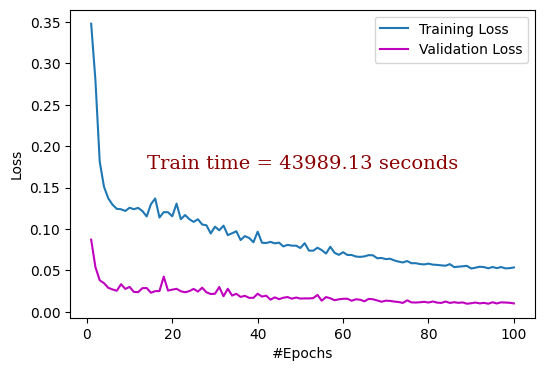

In [13]:
# plot of model_10
font = {'family': 'serif',
        'color':  'darkred',
        'weight': 'normal',
        'size': 14,
        }

epochs = range(1, len(train_loss_10) + 1)
plt.figure(figsize=(6, 4))

plt.plot(epochs, train_loss_10, label="Training Loss")
plt.plot(epochs, val_loss_10, label="Validation Loss", color='m')
#plt.text(0.5, 0.5, r'Train time = 43989.13 seconds', fontdict=font)
plt.text(
    0.5, 0.5,
    r'Train time = 43989.13 seconds',
    fontdict=font,
    ha='center', va='center',
    transform=plt.gca().transAxes
)

plt.xlabel("#Epochs")
plt.ylabel("Loss")
#plt.title("Training vs Validation Loss")
plt.legend()
#plt.xticks(epochs, rotation=45, ha="right")
#plt.grid(True)
#plt.savefig('epoch_loss_100.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
ckpt_best = torch.load(model_10_best_dir_loss, map_location="cpu")

print(ckpt_best.keys())
print(ckpt_best["epoch"])
print(ckpt_best["lr_schedulers"][0]['_last_lr'])
print(ckpt_best["train_losses"])
print(ckpt_best["val_losses"])

In [14]:
# plt.figure(figsize=(6, 4))

# plt.plot(epochs, train_loss_10, label="Train Loss")
# plt.plot(epochs, val_loss_10, label="Validation Loss")

# # annotate train loss
# for x, y in zip(epochs, train_loss_10):
#     plt.text(x, y, f'{y:.3f}', fontsize=8, ha='center', va='bottom')

# # annotate val loss
# for x, y in zip(epochs, val_loss_10):
#     plt.text(x, y, f'{y:.3f}', fontsize=8, ha='center', va='top')

# plt.xlabel("#Epochs")
# plt.ylabel("Loss")
# plt.legend()

# plt.show()

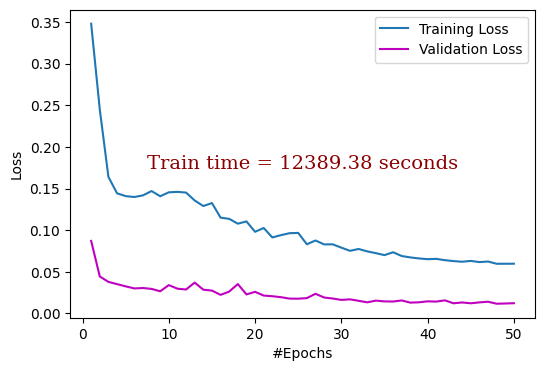

In [14]:
# plot for epochs=50
epochs = range(1, len(train_loss_5) + 1)
plt.figure(figsize=(6, 4))

plt.plot(epochs, train_loss_5, label="Training Loss")
plt.plot(epochs, val_loss_5, label="Validation Loss", color='m')
#plt.text(0.5, 0.5, r'Train time = 43989.13 seconds', fontdict=font)
plt.text(
    0.5, 0.5,
    r'Train time = 12389.38 seconds',
    fontdict=font,
    ha='center', va='center',
    transform=plt.gca().transAxes
)

plt.xlabel("#Epochs")
plt.ylabel("Loss")
#plt.title("Training vs Validation Loss")
plt.legend()
#plt.grid(True)
#plt.savefig('epoch_loss_50.png', dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
ckpt_best = torch.load(model_5_best_dir_loss, map_location="cpu")

print(ckpt_best.keys())
print(ckpt_best["epoch"])
print(ckpt_best["lr_schedulers"][0]['_last_lr'])
print(ckpt_best["train_losses"])
print(ckpt_best["val_losses"])

### Plot training loss of epoch 50 and 100

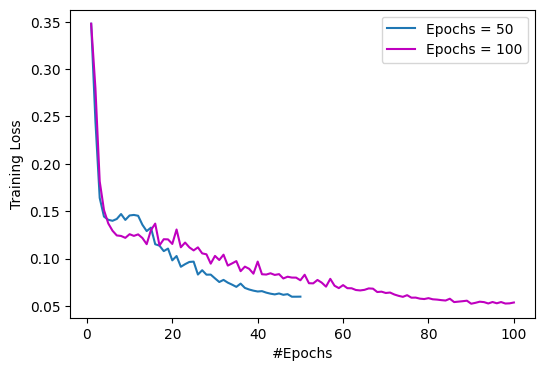

In [ ]:
# plot for epochs=50
epochs_50 = range(1, len(train_loss_5) + 1)
epochs_100 = range(1, len(train_loss_10) + 1)
plt.figure(figsize=(6, 4))

plt.plot(epochs_50, train_loss_5, label="Epochs = 50")
plt.plot(epochs_100, train_loss_10, label="Epochs = 100", color='m')
#plt.text(0.5, 0.5, r'Train time = 43989.13 seconds', fontdict=font)
# plt.text(
#     0.5, 0.5,
#     r'Train time = 12389.38 seconds',
#     fontdict=font,
#     ha='center', va='center',
#     transform=plt.gca().transAxes
# )

plt.xlabel("#Epochs")
plt.ylabel("Training Loss")
#plt.title("Training vs Validation Loss")
plt.legend()
#plt.grid(True)
#plt.savefig('epoch_compare_loss.png', dpi=300, bbox_inches='tight')

plt.show()

### FoMo-0D default model

In [18]:
model_default_aucroc_scores = []
model_default_aucpr_scores = []
model_default_f1_scores = []
model_default_time_per_instance = []
# walk through all folders and find result.csv files
for subdir, _, files in os.walk(default_dir):
    if "result.csv" in files:
        file_path = os.path.join(subdir, "result.csv")
        df = pd.read_csv(file_path)

        # extract scores
        aucroc = df['aucroc'].values[0]
        model_default_aucroc_scores.append(aucroc)

        aucpr = df['aucpr'].values[0]
        model_default_aucpr_scores.append(aucpr)

        f1 = df['f1'].values[0]
        model_default_f1_scores.append(f1)

        time_instance = df ['time-per-inst'].values[0]
        model_default_time_per_instance.append(time_instance)

# compute average scores of all datasets
model_default_avg_aucroc = sum(model_default_aucroc_scores) / len(model_default_aucroc_scores)
model_default_avg_aucpr = sum(model_default_aucpr_scores) / len(model_default_aucpr_scores)
model_default_avg_f1 = sum(model_default_f1_scores) / len(model_default_f1_scores)
model_default_time_per_instance_avg = sum(model_default_time_per_instance) / len(model_default_time_per_instance)

print(f"number of datasets: {len(model_default_aucroc_scores)}")
print(f"Average aucroc: {model_default_avg_aucroc}")
print(f"Average aucpr: {model_default_avg_aucpr}")
print(f"Average f1: {model_default_avg_f1}")
print(f"Inference time per instance: {model_default_time_per_instance_avg}")

number of datasets: 121
Average aucroc: 0.7590645511541744
Average aucpr: 0.4786638498057685
Average f1: 0.4666975187169514
Inference time per instance: 0.004876898293420036


In [21]:
default_ckpt_best = torch.load(default_dir_best_loss, map_location="cpu")

default_train_loss = default_ckpt_best["train_losses"]
default_val_loss = default_ckpt_best["val_losses"]
default_last_lr = default_ckpt_best["lr_schedulers"][0]['_last_lr']

print(ckpt_best.keys())
print(ckpt_best["epoch"])
print(ckpt_best["lr_schedulers"][0]['_last_lr'])
print(ckpt_best["train_losses"])
print(ckpt_best["val_losses"])

dict_keys(['epoch', 'global_step', 'pytorch-lightning_version', 'state_dict', 'loops', 'callbacks', 'optimizer_states', 'lr_schedulers', 'train_losses', 'val_losses'])
176
[5.6898210384392636e-05]
[0.3530936672091484, 0.22118934513628483, 0.19449573887884616, 0.18302294277399778, 0.16882225830852984, 0.15302769453823567, 0.14955122397094964, 0.1379339844882488, 0.13122116221487523, 0.13198333121091127, 0.12643660055845976, 0.12442185747995972, 0.12019064691103995, 0.12225950442254543, 0.1220540315695107, 0.12125767922773957, 0.11428656757622957, 0.11496408954076469, 0.11343354450538755, 0.11380944141745568, 0.11144389205798506, 0.10914460260421038, 0.10957701573893427, 0.11238893181085587, 0.10739733273535967, 0.10888246111944318, 0.1065460502691567, 0.10622394962795079, 0.10940962253883481, 0.1066176240555942, 0.10453927249461413, 0.10772572416812182, 0.10904807196930051, 0.10469955979660153, 0.10809728135168552, 0.10660232323408127, 0.10609049171954393, 0.1067488398104906, 0.10231466

#### Plot train loss of epoch=50, epoch=100, and the FoMo-0D default

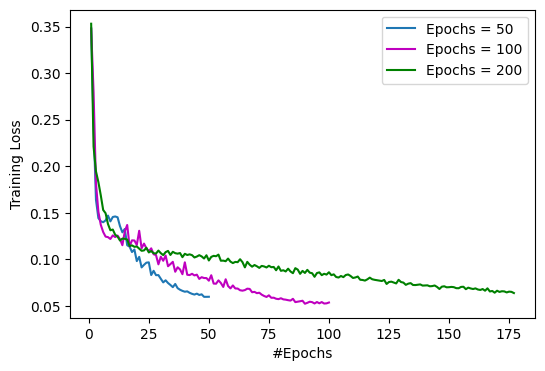

In [22]:
# plot for epochs=50
epochs_50 = range(1, len(train_loss_5) + 1)
epochs_100 = range(1, len(train_loss_10) + 1)
epochs_default = range(1, len(default_train_loss) + 1)
plt.figure(figsize=(6, 4))

plt.plot(epochs_50, train_loss_5, label="Epochs = 50")
plt.plot(epochs_100, train_loss_10, label="Epochs = 100", color='m')
plt.plot(epochs_default, default_train_loss, label="Epochs = 200", color='green')

#plt.text(0.5, 0.5, r'Train time = 43989.13 seconds', fontdict=font)
# plt.text(
#     0.5, 0.5,
#     r'Train time = 12389.38 seconds',
#     fontdict=font,
#     ha='center', va='center',
#     transform=plt.gca().transAxes
# )

plt.xlabel("#Epochs")
plt.ylabel("Training Loss")
#plt.title("Training vs Validation Loss")
plt.legend()
#plt.grid(True)
#plt.savefig('epoch_compare_loss.png', dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
# fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(10,6))
# epochs = []
# train_losses = [train_loss_1, train_loss_2, train_loss_3, train_loss_4, train_loss_5, train_loss_6, train_loss_7, train_loss_8, train_loss_9, train_loss_10]
# val_losses = [val_loss_1, val_loss_2, val_loss_3, val_loss_4, val_loss_5, val_loss_6, val_loss_7, val_loss_8, val_loss_9, val_loss_10]
# for i, ax in enumerate(axes.flatten()):
#     if i < len(train_losses):
#         ax.plot(range(1, len(train_losses[i]) + 1), train_losses[i], label="Train Loss")
#         ax.plot(range(1, len(train_losses[i]) + 1), val_losses[i], label="Validation Loss")

#         #ax.xlabel("#Epochs")
#         #ax.ylabel("Loss")
#         ax.legend()
#     else:
#         break

### Visualization

In [16]:
models = ['model_1', 'model_2', 'model_3', 'model_4', 'model_5', 'model_6', 'model_7', 'model_8', 'model_9', 'model_10']
epochs = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

avg_aucroc_scores = [round(model_1_avg_aucroc, 4), round(model_2_avg_aucroc, 4), round(model_3_avg_aucroc, 4), round(model_4_avg_aucroc, 4), round(model_5_avg_aucroc, 4), round(model_6_avg_aucroc, 4), round(model_7_avg_aucroc, 4), round(model_8_avg_aucroc, 4), round(model_9_avg_aucroc, 4), round(model_10_avg_aucroc, 4)]
avg_aucpr_scores = [round(model_1_avg_aucpr, 4), round(model_2_avg_aucpr, 4), round(model_3_avg_aucpr, 4), round(model_4_avg_aucpr, 4), round(model_5_avg_aucpr, 4), round(model_6_avg_aucpr, 4), round(model_7_avg_aucpr, 4), round(model_8_avg_aucpr, 4), round(model_9_avg_aucpr, 4), round(model_10_avg_aucpr, 4)]
avg_f1_scores = [round(model_1_avg_f1, 4), round(model_2_avg_f1, 4), round(model_3_avg_f1, 4), round(model_4_avg_f1, 4), round(model_5_avg_f1, 4), round(model_6_avg_f1, 4), round(model_7_avg_f1, 4), round(model_8_avg_f1, 4), round(model_9_avg_f1, 4), round(model_10_avg_f1, 4)]
# training time is in seconds
training_time = [round(model_1_train_time, 2), round(model_2_train_time, 2), round(model_3_train_time, 2), round(model_4_train_time, 2), round(model_5_train_time, 2), round(model_6_train_time, 2), round(model_7_train_time, 2), round(model_8_train_time, 2), round(model_9_train_time, 2), round(model_10_train_time, 2)]
# inference time is in microseconds (µs)
inference_time = [model_1_time_per_instance_avg * 1e6, model_2_time_per_instance_avg * 1e6, model_3_time_per_instance_avg * 1e6, model_4_time_per_instance_avg * 1e6, model_5_time_per_instance_avg * 1e6, model_6_time_per_instance_avg * 1e6, model_7_time_per_instance_avg * 1e6, model_8_time_per_instance_avg * 1e6, model_9_time_per_instance_avg * 1e6, model_10_time_per_instance_avg * 1e6]

summary_dict = {'models': models, 'epochs': epochs,'average_aucroc': avg_aucroc_scores, 'average_aucpr': avg_aucpr_scores, 'average_f1': avg_f1_scores, 'training_time(s)': training_time, 'inference_time(µs)': inference_time}


In [17]:
summary_results = pd.DataFrame(summary_dict)

In [18]:
summary_results

,models,epochs,average_aucroc,average_aucpr,average_f1,training_time(s),inference_time(µs)
0,model_1,10,0.7333,0.4213,0.4183,2470.71,4.979172
1,model_2,20,0.7390,0.4290,0.4236,4964.26,5.010530
2,model_3,30,0.7202,0.4090,0.4066,9731.51,10.350581
3,model_4,40,0.7268,0.4124,0.4135,10042.91,4.905367
4,model_5,50,0.7345,0.4080,0.4085,12389.38,5.034104
5,model_6,60,0.7181,0.3974,0.3944,17452.05,4.988317
6,model_7,70,0.7204,0.3973,0.3953,19882.01,7.447774
7,model_8,80,0.7275,0.4034,0.4033,31122.83,9.022722
8,model_9,90,0.7226,0.3984,0.3947,36202.58,8.720716
9,model_10,100,0.7167,0.3982,0.4026,43989.13,5.121944


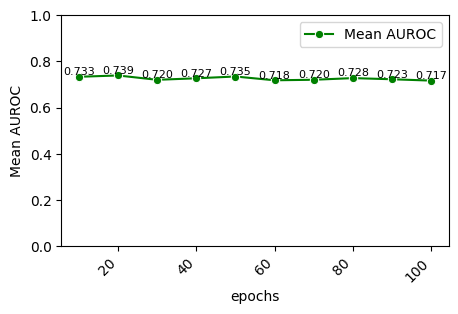

In [20]:
plt.figure(figsize=(5, 3))
sns.lineplot(data=summary_results, x="epochs", y="average_aucroc", marker='o', label='Mean AUROC', color='green')
for x, y in zip(summary_results['epochs'], summary_results['average_aucroc']):
    plt.text(x, y, f'{y:.3f}', fontsize=8, ha='center', va='bottom')
plt.ylim(0,1)
plt.ylabel('Mean AUROC')
#plt.title("Mean AUCROC comparison across models")
plt.xticks(rotation=45, ha="right")
plt.show()

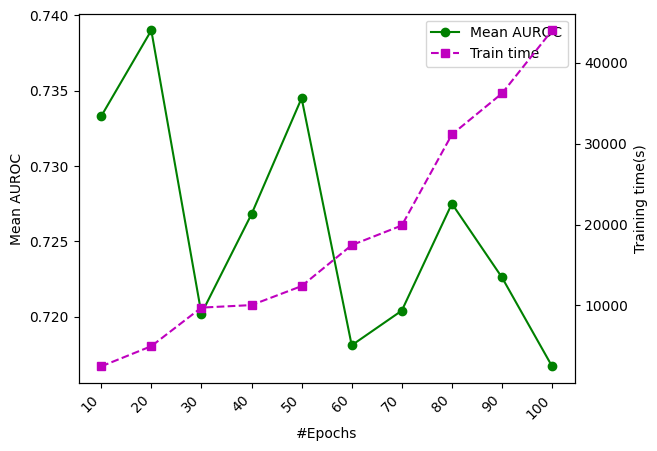

In [ ]:
x = summary_results['epochs']  

fig, ax1 = plt.subplots()

# First axis (AUROC)
line1, = ax1.plot(x, summary_results['average_aucroc'], marker='o', label='Mean AUROC', color='green')
ax1.set_xlabel('#Epochs')
ax1.set_ylabel('Mean AUROC')
plt.xticks(x, rotation=45, ha="right")
# for x_val, y_val in zip(x, summary_results['average_aucroc']):
#     ax1.text(
#         x_val, y_val,
#         f'{y_val:.3f}',
#         fontsize=8,
#         ha='center',
#         va='top',
#     )

#plt.legend()

# Second axis (Train Time)
ax2 = ax1.twinx()
line2, = ax2.plot(x, summary_results['training_time(s)'], marker='s', label='Train time', color='m', linestyle='dashed')
ax2.set_ylabel('Training time(s)')

lines = [line1, line2]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

#plt.title('Mean AUROC vs Train Time')

#plt.legend()
#plt.savefig('epoch_mean_auroc_train_time.png', dpi=300, bbox_inches='tight')
plt.show()

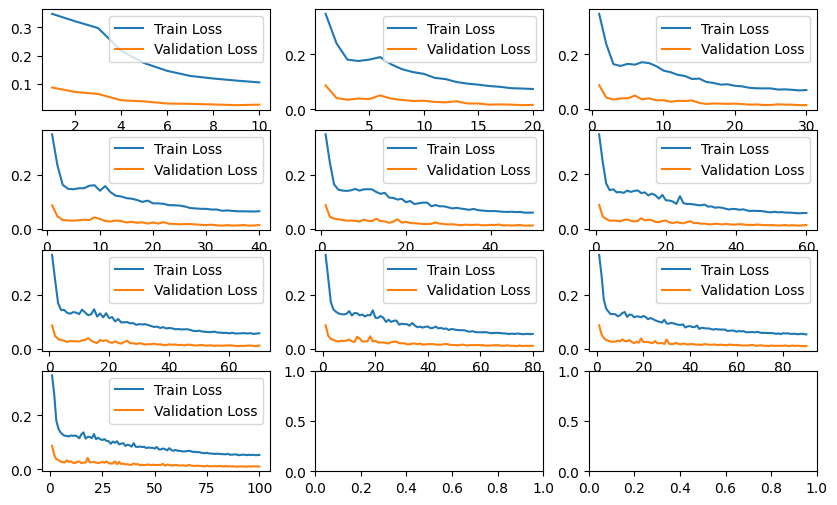

In [22]:
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(10,6))
epochs = []
train_losses = [train_loss_1, train_loss_2, train_loss_3, train_loss_4, train_loss_5, train_loss_6, train_loss_7, train_loss_8, train_loss_9, train_loss_10]
val_losses = [val_loss_1, val_loss_2, val_loss_3, val_loss_4, val_loss_5, val_loss_6, val_loss_7, val_loss_8, val_loss_9, val_loss_10]
for i, ax in enumerate(axes.flatten()):
    if i < len(train_losses):
        ax.plot(range(1, len(train_losses[i]) + 1), train_losses[i], label="Train Loss")
        ax.plot(range(1, len(train_losses[i]) + 1), val_losses[i], label="Validation Loss")

        #ax.xlabel("#Epochs")
        #ax.ylabel("Loss")
        ax.legend()
    else:
        break